<a href="https://colab.research.google.com/github/Laila-Qodariah/pm-turi4-clustering/blob/main/pm_turi4_clustering_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Latihan PRAKTIKUM 4

Langkah 1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
data_simulasi = {
    'usia': np.random.randint(18, 70, 150),
    'pendapatan': np.random.randint(3, 150, 150),
    'skor_belanja': np.random.randint(1, 100, 150)
}
df = pd.DataFrame(data_simulasi)
X_scaled = StandardScaler().fit_transform(df[['usia', 'pendapatan', 'skor_belanja']])

print(df.head())

   usia  pendapatan  skor_belanja
0    40          30            98
1    49          72            17
2    27          30            43
3    27          56            80
4    53          67            66


Langkah 2

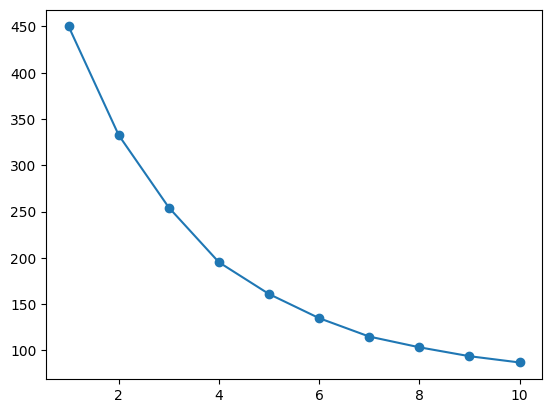

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

Langkah 3

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print("Jumlah anggota di tiap cluster:")
print(df['cluster'].value_counts())


Jumlah anggota di tiap cluster:
cluster
1    53
0    49
2    48
Name: count, dtype: int64


Langkah 4

In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.26326749246755626


Langkah 5

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        47.8        44.5          25.6
1        49.2        65.4          81.2
2        31.8       106.2          48.8


6.	Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [ ]:
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
label_3 = kmeans_3.fit_predict(X_scaled)
score = silhouette_score(X_scaled, label_3)

kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label_5 = kmeans_5.fit_predict(X_scaled)
score_5 = silhouette_score(X_scaled, label_5)

print(f"Silhouette Score K=3 : {score:.4f}")
print(f"Silhouette Score K=5 : {score_5:.4f}")

Silhouette Score K=3 : 0.2633
Silhouette Score K=5 : 0.2859


7.	Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [ ]:
label_tanpa_scaling = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])
score_tanpa_scaling = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], label_tanpa_scaling)
print(f"Silhouette Score (Tanpa Scaling, K=3): {score_tanpa_scaling:.4f}")

Silhouette Score (Tanpa Scaling, K=3): 0.3600


8.	Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

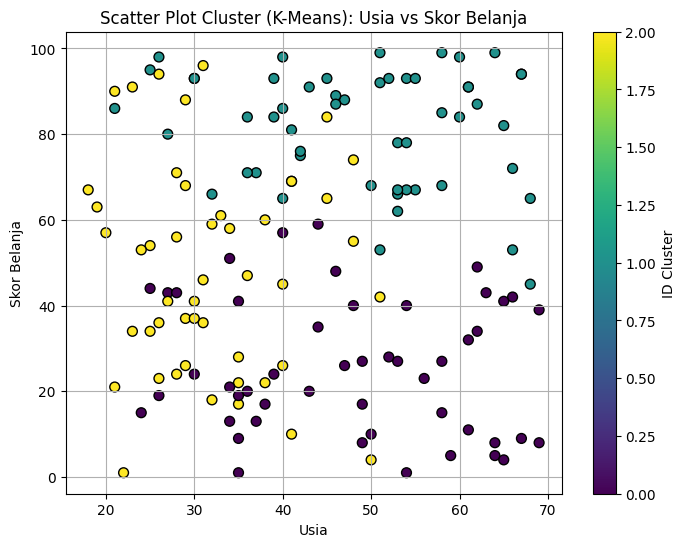

In [ ]:
# Scatter plot cluster: usia (x) vs skor_belanja (y)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=50, edgecolor='k')

plt.title('Scatter Plot Cluster (K-Means): Usia vs Skor Belanja')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.grid(True)
plt.colorbar(label='ID Cluster')
plt.show()

9.	Bagaimana K-Means menemukan kelompok tanpa label?

K-Means menemukan kelompok tanpa label melalui siklus sederhana berikut:
- Menaruh pusat acak: Meletakkan beberapa titik pusat (centroid) secara acak di dalam data.
- Mengelompokkan data: Memasukkan setiap data ke titik pusat yang jaraknya paling dekat.
- Menggeser pusat: Memindahkan posisi titik pusat ke rata-rata dari seluruh anggota kelompoknya.
- Mengulang proses: Terus mengulang langkah 2 dan 3 sampai posisi titik pusatnya tidak berpindah lagi (stabil).

10.	Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Metode Elbow menunjukkan siku di K=3 karena titik tersebut adalah batas paling ideal:Sebelum K=3: Menambah jumlah kelompok membuat data jauh lebih rapi secara drastis.   Setelah K=3: Menambah kelompok lagi sudah tidak memberikan perubahan yang berarti (grafiknya mulai mendatar).   Makanya, garis pada grafik berbelok menyerupai bentuk "siku" tepat di angka 3.   

11.	Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

- Mengapa scaling penting:
Agar semua fitur (seperti usia dan pendapatan) memiliki pengaruh yang adil dan seimbang saat komputer menghitung jarak antar-data.   
- Dampak jika dilewatkan:
Fitur dengan angka yang besar (seperti pendapatan) akan mendominasi perhitungan, sedangkan fitur berangka kecil (seperti usia) jadi tidak diperhitungkan. Akibatnya, hasil pengelompokan (clustering) menjadi bias dan tidak akurat.